## kNN Example

Our goal is to use the wine classification data set in order to make wine recommendations. For example, if someone likes a given kind of wine, we could recommend them similar wines. 

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_wine #<--- new
from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier #<--- new
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [29]:
# bring in the dataset
# see https://scikit-learn.org/1.5/modules/generated/sklearn.datasets.load_wine.html
wine_data = load_wine(as_frame=True)
df = wine_data.frame
wine_data

{'data':      alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
 0      14.23        1.71  2.43               15.6      127.0           2.80   
 1      13.20        1.78  2.14               11.2      100.0           2.65   
 2      13.16        2.36  2.67               18.6      101.0           2.80   
 3      14.37        1.95  2.50               16.8      113.0           3.85   
 4      13.24        2.59  2.87               21.0      118.0           2.80   
 ..       ...         ...   ...                ...        ...            ...   
 173    13.71        5.65  2.45               20.5       95.0           1.68   
 174    13.40        3.91  2.48               23.0      102.0           1.80   
 175    13.27        4.28  2.26               20.0      120.0           1.59   
 176    13.17        2.59  2.37               20.0      120.0           1.65   
 177    14.13        4.10  2.74               24.5       96.0           2.05   
 
      flavanoids  nonflavanoid

The wine dataset has built-in description information with it as well. Note the dataset contains observations that fit into one of three classes of wines. 

In [25]:
wine_data.DESCR

'.. _wine_dataset:\n\nWine recognition dataset\n------------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 178\n:Number of Attributes: 13 numeric, predictive attributes and the class\n:Attribute Information:\n    - Alcohol\n    - Malic acid\n    - Ash\n    - Alcalinity of ash\n    - Magnesium\n    - Total phenols\n    - Flavanoids\n    - Nonflavanoid phenols\n    - Proanthocyanins\n    - Color intensity\n    - Hue\n    - OD280/OD315 of diluted wines\n    - Proline\n    - class:\n        - class_0\n        - class_1\n        - class_2\n\n:Summary Statistics:\n\n============================= ==== ===== ======= =====\n                                Min   Max   Mean     SD\n============================= ==== ===== ======= =====\nAlcohol:                      11.0  14.8    13.0   0.8\nMalic Acid:                   0.74  5.80    2.34  1.12\nAsh:                          1.36  3.23    2.36  0.27\nAlcalinity of Ash:            10.6  30.0    19.5   3.3\nMagnesium:      

Do we have balance among classes of the dataset?

In [31]:
# check the percentage representation of the classes
df["target"].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

Let's visualize this data. I'll just use the first two features now and the target as the class/hue.

<Axes: xlabel='alcohol', ylabel='malic_acid'>

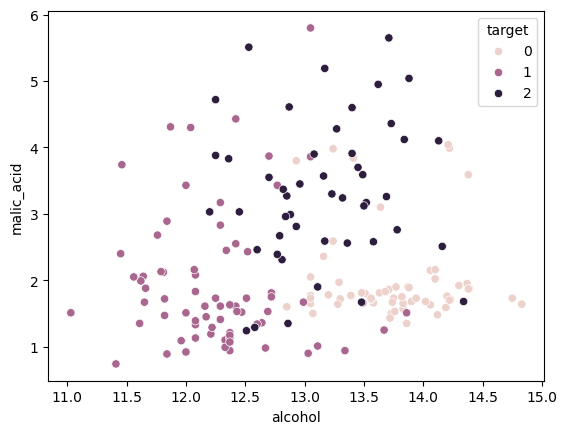

In [33]:
sns.scatterplot(x=df['alcohol'], y=df['malic_acid'], hue=df['target'])

Are we missing data?

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

No data appears to be missing.

To avoid overfitting, let's try to use only the independent variables we really need.  We can use the correlation matrix to help us understand which independent features are strongly correlated. 

<Axes: >

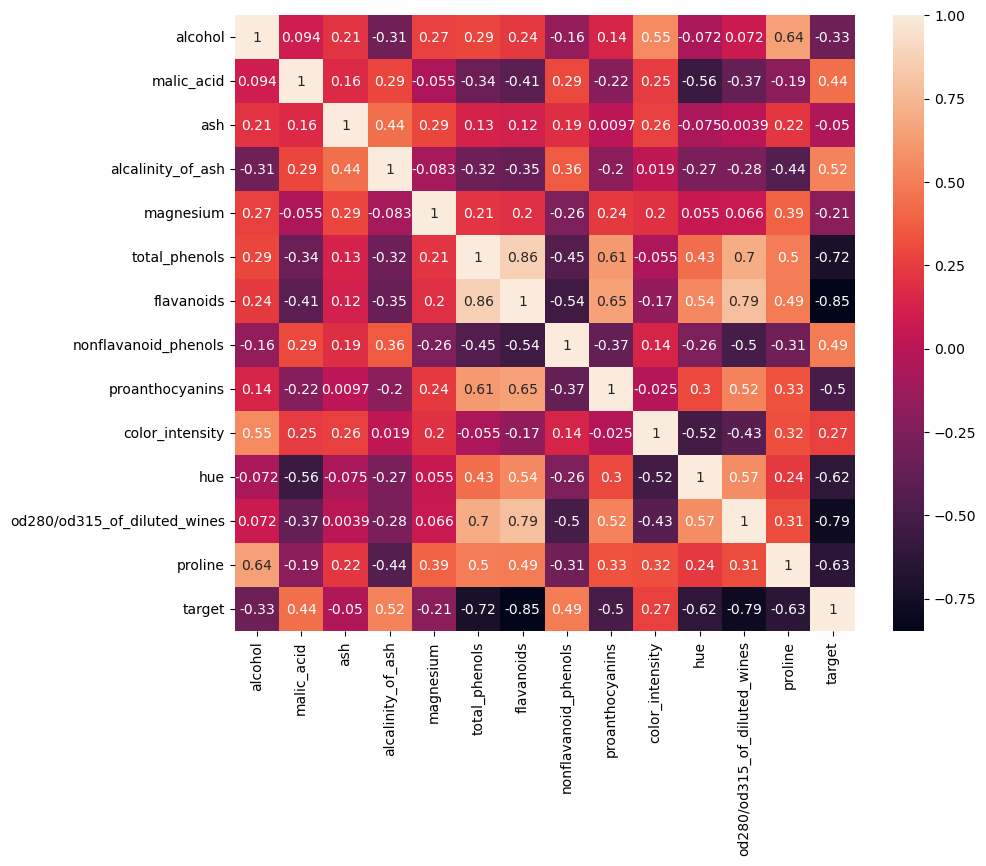

In [39]:
plt.subplots(figsize= (10, 8))
sns.heatmap(df.corr(), annot=True)

We should normalize the data, otherwise calculations will be heavily weighted when numbers are bigger. To avoid this, we normalize. 

We also only do this for the training data. If we also did this for our test data, it would be influenced by the training data and we don't want the influence. We need to keep the data sets separate.

This is also sensitive to outliers, so we should remove outliers first as well.

In [ ]:
# quick visual inspection with box plots 


In [41]:
# loop to remove outliers
for i in df.columns:
    # find z-scores
    if i != "target":
        mean = df[i].mean()
        std =  df[i].std()

        # we can add this as a new feature and then filter by it to drop rows
        df["z_score"] = (df[i] - mean)/std

        # want to know what I am removing
        print(df[(df["z_score"] <= -3) | (df["z_score"] >= 3)])
        
        # remove rows that don't fall into range (removing outliers)
        df = df[(df["z_score"] > -3) & (df["z_score"] < 3)]
        
df = df.drop(['z_score'], axis=1)

Empty DataFrame
Columns: [alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins, color_intensity, hue, od280/od315_of_diluted_wines, proline, target, z_score]
Index: []
     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
123    13.05         5.8  2.13               21.5       86.0           2.62   

     flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
123        2.65                   0.3             2.01              2.6  0.73   

     od280/od315_of_diluted_wines  proline  target   z_score  
123                           3.1    380.0       1  3.100446  
     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
25     13.05        2.05  3.22               25.0      124.0           2.63   
59     12.37        0.94  1.36               10.6       88.0           1.98   
121    11.56        2.05  3.23               28.5      119.0           3.18   


Let's split the data set. We'll use a 75/25 split.

In [45]:
# define independent variables as big/uppercase X
X = df.iloc[:, 0:13]
X.drop(['flavanoids'], axis = 1, inplace=True) # to avoid overfitting

# define dependent variable as y
y = df['target']

# we'll split it 75/25, using 25% for training
# random_state - sets will be random each time. To have reproducible sets, use a digit here as your seed.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

Now let's apply the standard scaler.

In [49]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

Now let's set up the model using the training data.

In [53]:
# create model
knn = KNeighborsClassifier(n_neighbors=9)

# fit the model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=9)

Now that we have the model, let's do a prediction. Run this against our test data to see how it does. 

In [55]:
# predict using test data and set as y_pred
y_pred = knn.predict(X_test)

In [57]:
# Print confusion matrix 
metrics.confusion_matrix(y_pred, y_test)

array([[16,  0,  0],
       [ 0, 15,  0],
       [ 0,  1, 10]], dtype=int64)

In [ ]:
# had to update scikit package in conda for this to work
# conda update scikit-learn

In [59]:
# Calculate accuracy score
accuracy_score(y_pred, y_test)

0.9761904761904762

Question: What if we try other k values?  How do we determine optimum k? Note that cross-validation can be helpful here. Need a good k to prevent overfitting and underfitting.

## Now you try!
Let's use knn to classify iris flowers into one of the three species. 

1. Load the built-in iris dataset

In [ ]:
from sklearn.datasets import load_iris
# load iris
iris = load_iris(as_frame=True)
# get data frame
df = iris.frame

df.head()

2. Explore the data

In [ ]:
# basic metadata
print(df.info())

# basic stats
print(df.describe())

In [ ]:
# explore class balance using value_counts()


3. Split the data 80/20. Use random seed 42.

In [ ]:
X = 
y = 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

3.5 What do you have to do to the training data to get it ready? 

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transformation(X_train)
X_test = scaler.fit_transformation(X_test)

4. Train the knn model

In [51]:
knn = KNeighborsClassifier(n_neighbors=9)


5. Evaluate the performance

In [ ]:
# predict performance

# show confusion matrix

# determine accuracy


6. Go back and try different k values. What do you learn?

In [ ]:
# can try something like this
accuracies = []
k_values = range(1, 21)
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    accuracies.append(knn.score(X_test, y_test))

plt.plot(k_values, accuracies, marker='o')
plt.title("KNN Accuracy vs. Number of Neighbors")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.show()